# PDE 1 notebook

## Lapace equation

The Laplace equation is common in Physics:

$$
\nabla^2 \phi = 0
$$

Here, $\nabla$ can represent the electric potential in free space, the gravitational potential away from any mass, the steady-state heat temperature distribution, etc.

To solve it, we discretize the derivatives and vectorize the problem. For a 2D grid, we end up with the equation:

$$
\phi(x, y) = \frac{1}{4}\left[\phi(x+a,y) + \phi(x-a, y) + \phi(x, y+a) + \phi(x, y-a)\right]
$$

Every point is the average of the points around it. To solve this problem, we use the relaxation method. 

In the example below, we consider the electric potential in a region of space of 1 m by 1 m mapped onto a 101x101 matrix. Hence, $a = 0.01$ m. Three sides of the box ($x = 0$, $x = 1$, and $y = 0$) are grounded with $\phi = 0$ V. On the last edge ($y = 1$), the voltage is defined as:

$$
\phi(x, 1) = 5\sin(2\pi x)
$$

We can track how the voltage in space ($\phi$) evolves during each iteration of the relaxation.

In [38]:
import numpy as np 
import matplotlib.pyplot as plt 
from matplotlib import animation 
from IPython.display import HTML
from functools import partial

# Constants
N = 101
target = 1e-4
L = 1
frame_interval = 20    # Number of steps between save frames for animation

# x axis
x = np.linspace(0, L, num = N, endpoint=True)

# Edge voltage
def edge(x):
    return 5*np.sin(2*np.pi*x)

def update_fig(frame, im, line, phi_anim, iters, error):
    im.set_array(phi_anim[frame])
    line.set_data(iters[:frame],error[:frame])
    return im, line

# Initialize the voltage
def init(f, x, N):
    phi = np.zeros((N,N), dtype="float")
    phi[-1,:] = f(x)
    phiprime = np.empty((N,N), dtype="float")

    return phi, phiprime

# One relaxation step
def relax_anim(x, N, target):

    phi, phiprime = init(edge, x, N)
    phi_anim = [phi.copy()]
    delta_anim = []

    counter_anim = 0
    counter = 0
    delta = 1

    while delta > target:
        for i in range(N):
            for j in range(N):
                if i==0 or i==N-1 or j==0 or j==N-1:
                    phiprime[i,j] = phi[i,j]
                else:
                    phiprime[i,j] = (phi[i+1,j]+phi[i-1,j]+phi[i,j+1]+phi[i,j-1])/4.0

        # Calculate the max error
        delta = np.max(np.abs(phi-phiprime))

        # Swap the two arrays
        phi, phiprime = phiprime, phi

        counter += 1

        if counter % frame_interval == 0:
            counter_anim += 1
            phi_anim.append(phi.copy())
            delta_anim.append(delta)

    return phi, np.array(phi_anim), counter, counter_anim, np.array(delta_anim)

# Run the relaxation
phi, phi_anim, counter, counter_anim, delta_anim = relax_anim(x, N, target)

print(f"Ran for {counter} iteration. Saved {counter_anim} frames for animation")

iters = frame_interval * np.arange(1, len(delta_anim) + 1)

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(14,6))
im = axes[0].imshow(phi_anim[0,:,:], origin="lower", extent=[0,L,0,L])
line, = axes[1].plot([], [])
axes[1].set_xlim(0, iters[-1])
axes[1].set_ylim(delta_anim.min(), delta_anim.max())
axes[1].set_yscale('log')

ani = animation.FuncAnimation(fig, partial(update_fig, im = im, line = line,phi_anim=phi_anim, iters=iters, error=delta_anim), frames = len(phi_anim), repeat=False)

plt.close(fig)

HTML(ani.to_html5_video())

Ran for 1884 iteration. Saved 94 frames for animation


If we pay attention to the relaxation above, we always start from the corner $(x = 0, y = 0)$ and move out across the whole space in rows along the horizontal ($x$) direction. We have to relax the array *one point at a time*. For small matrices, this is fine. But if we deal with larger systems and/or want to parallelize the solution, it is a poor choice. 

An alternative choice of sweeping through the array is to use the "red-black" checkered approach. There, we only split the array into two arrays offset from each other. On any give iteration, the value of each point on the red array is the average of its black neighbors that are not changing. Then we consider the black array where each point is the average of its red neighbors that are held constant. All of these calculations can be done in parallel and it will often converge faster, even for serialized computation because it depends less on the boundary conditions.

We implement this strategy below.

In [39]:
def relax_red_black(x, N, target):

    phi, phiprime = init(edge, x, N)
    phi_anim = [phi.copy()]
    delta_anim = []

    counter_anim = 0
    counter = 0
    delta = 1

    while delta > target:
        delta = 0.0
        for parity in (0, 1):
            for i in range(1, N-1):
                # First interior j in row i with (i+j) % 2 == parity, then every second point
                for j in range(1 + (i + 1 + parity) % 2, N-1, 2):
                    new = (phi[i+1,j]+phi[i-1,j]+phi[i,j+1]+phi[i,j-1])/4.0
                    delta = max(delta, abs(new - phi[i,j]))
                    phi[i,j] = new

        counter += 1

        if counter % frame_interval == 0:
            counter_anim += 1
            phi_anim.append(phi.copy())
            delta_anim.append(delta)

    return phi, np.array(phi_anim), counter, counter_anim, np.array(delta_anim)

# Run the relaxation
phi, phi_anim, counter, counter_anim, delta_anim = relax_red_black(x, N, target)

print(f"Ran for {counter} iteration. Saved {counter_anim} frames for animation")

iters = frame_interval * np.arange(1, len(delta_anim) + 1)

# Create figure
fig2, axes2 = plt.subplots(1, 2, figsize=(14,6))
im2 = axes2[0].imshow(phi_anim[0,:,:], origin="lower", extent=[0,L,0,L])
line2, = axes2[1].plot([], [])
axes2[1].set_xlim(0, iters[-1])
axes2[1].set_ylim(delta_anim.min(), delta_anim.max())
axes2[1].set_yscale('log')

ani2 = animation.FuncAnimation(fig2, partial(update_fig, im = im2, line = line2,phi_anim=phi_anim, iters=iters, error=delta_anim), frames = len(phi_anim), repeat=False)

plt.close(fig2)

HTML(ani2.to_html5_video())

Ran for 1180 iteration. Saved 59 frames for animation


For the initial strategy, we required 1884 iterations that must happen in series.

For the red-black strategy, we required 1180 iterations that can be parallelized.

## Poisson equation

Another common set of physical systems is described by Poisson equation. For example, if we allow for non-zero charge density in space, the equation for the electric potential is:

$$
\nabla^2\phi = \frac{-\rho}{\epsilon_0}
$$

The solution becomes:

$$
\phi(x, y) = \frac{1}{4}\left[\phi(x+a,y) + \phi(x-a, y) + \phi(x, y+a) + \phi(x, y-a)\right] + \frac{a^2}{4\epsilon_0}\rho(x, y)
$$

We can use the same geometry as above. A box of 1 m per side with 101 points per dimension. Here, we will ground all four sides of the box and set a region at $+10$ Cm$^{-2}$ in the box $0.6 < x < 0.8$ and $0.6 < y < 0.8$ and another region at $-10$ Cm$^{-2}$ in the box $0.2 < x < 0.4$ and $0.2 < y < 0.4$. 

In [40]:
target = 1e-5

def relax_red_black_2(x, N, target):

    phi = np.zeros((N,N), dtype="float")
    phi_anim = [phi.copy()]
    delta_anim = []
    a = x[1]-x[0]

    counter_anim = 0
    counter = 0
    delta = 1

    while delta > target:
        delta = 0.0
        for parity in (0, 1):
            for i in range(1, N-1):
                # First interior j in row i with (i+j) % 2 == parity, then every second point
                for j in range(1 + (i + 1 + parity) % 2, N-1, 2):
                    if i >= 20 and i <= 40 and j >= 20 and j <=40:
                        new = (phi[i+1,j]+phi[i-1,j]+phi[i,j+1]+phi[i,j-1])/4.0 - a**2*10/4   # Set epsilon_0 = 0
                    elif i >= 60 and i <= 80 and j >= 60 and j <=80:
                        new = (phi[i+1,j]+phi[i-1,j]+phi[i,j+1]+phi[i,j-1])/4.0 + a**2*10/4   # Set epsilon_0 = 0
                    else:
                        new = (phi[i+1,j]+phi[i-1,j]+phi[i,j+1]+phi[i,j-1])/4.0
                    delta = max(delta, abs(new - phi[i,j]))
                    phi[i,j] = new

        counter += 1

        if counter % frame_interval == 0:
            counter_anim += 1
            phi_anim.append(phi.copy())
            delta_anim.append(delta)

    return phi, np.array(phi_anim), counter, counter_anim, np.array(delta_anim)

# Run the relaxation
phi, phi_anim, counter, counter_anim, delta_anim = relax_red_black_2(x, N, target)

print(f"Ran for {counter} iteration. Saved {counter_anim} frames for animation")

iters = frame_interval * np.arange(1, len(delta_anim) + 1)

# Create figure
fig3, axes3 = plt.subplots(1, 2, figsize=(14,6))
vmax = np.abs(phi).max()
im3 = axes3[0].imshow(phi_anim[0,:,:], origin="lower", extent=[0,L,0,L],
                      cmap="RdBu_r", vmin=-vmax, vmax=vmax)
line3, = axes3[1].plot([], [])
axes3[1].set_xlim(0, iters[-1])
axes3[1].set_ylim(delta_anim.min(), delta_anim.max())
axes3[1].set_yscale('log')

ani3 = animation.FuncAnimation(fig3, partial(update_fig, im = im3, line = line3,phi_anim=phi_anim, iters=iters, error=delta_anim), frames = len(phi_anim), repeat=False)

plt.close(fig3)

HTML(ani3.to_html5_video())

Ran for 1196 iteration. Saved 59 frames for animation


## Neuman boundary conditions

The systems we have analyzed so far are example of Dirichlet boundary conditions, where the value of the function is set at the boundary. Another common class of problems set the derivatives at the boundary. Just like the Dirichlet problems, the derivative can be set to anything. But here, we only consider $\partial\phi/\partial x = \partial\phi/\partial y = 0$. 

We can use the same geometry as above. A box of 1 m per side with 101 points per dimension. Here, we will ground all four sides of the box and set a region at $T_2 = 100.0$ degC in the box $0.6 < x < 0.8$ and $0.6 < y < 0.8$ and another region at $T_1 = 0.0$ degC in the box $0.2 < x < 0.4$ and $0.2 < y < 0.4$. 

Heat diffusion is governed by the following equation:

$$
D\nabla^2 T = \frac{\partial T}{\partial t}
$$

where $D$ is the thermal diffusivity. When the system reaches equilibrium, we get:

$$
\nabla^2 T = 0
$$

25.0
12.5
7.8125
6.25
4.6875
4.0283203125
3.4912109375
3.0548095703125
2.69775390625
2.4026870727539062
2.1562576293945312
1.9483327865600586
1.826561987400055
1.7142288386821747
1.6110594384372234
1.5164603013545275
1.4298136928118765
1.3503198482794687
1.2774539092788473
1.2103637578547932
1.1487629308703617
1.0917504469148298
1.0393210770502037
0.990672982958074
0.9562129516930362
0.9237139941121093
0.8922414956265712
0.8627409569146067
0.8340502630730704
0.8073087697322023
0.7811564900647312
0.7569141135583344
0.7330534144365046
0.7110550193916154
0.6892518141613664
0.6692589607190698
0.6492987326352662
0.63109446516372
0.6127842811433695
0.596174204406978
0.5828848222891132
0.5695359496994428
0.5576111897602871
0.5449952152425439
0.5338078954312557
0.5218925153977914
0.5113991864708431
0.5001487828971136
0.4903050106842386
0.47968266990549324
0.4704446029075058
0.46041342867846424
0.4517387610053376
0.4422627119456024
0.43411124323560557
0.4251556490596542
0.41748957707183365
0.40

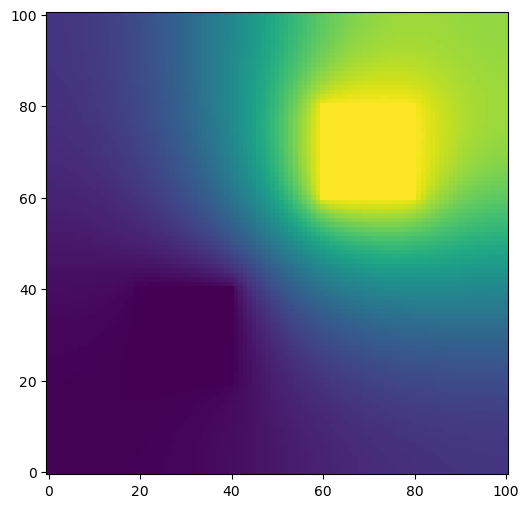

In [47]:
import numpy as np 
import matplotlib.pyplot as plt 

# Constants
L = 1.0
N = 101
T1 = 0.0
T2 = 100.0
target = 1e-2

# Create arrays
T = np.zeros((N,N), dtype="float")
for i in range(20,41):
    for j in range(20,41):
        T[i,j] = T1
for i in range(60,81):
    for j in range(60,81):
        T[i,j] = T2
Tprime = np.empty((N,N), dtype="float")

delta = 1.0
while delta>target:
    # Calculate the corners
    Tprime[0,0] = (T[0,1]+T[1,0])/2.0
    Tprime[0,-1] = (T[0,-2] + T[1,-1])/2.0
    Tprime[-1,0] = (T[-1,1] + T[-2,0])/2.0
    Tprime[-1,-1] = (T[-1,-2] + T[-2,-1])/2.0

    # Calculate the edges
    for i in range(1,N-1):
        Tprime[0,i] = (T[0,i-1] + T[0,i+1] + T[1,i])/3.0
        Tprime[-1,i] = (T[-1,i-1] + T[-1, i+1] + T[-2,i])/3.0
        Tprime[i,0] = (T[i-1,0] + T[i+1,0] + T[i,1])/3.0
        Tprime[i,-1] = (T[i-1,-1] + T[i+1,-1] + T[i,-2])/3.0

    # Calculate the interior
    for i in range(1,N-1):
        for j in range(1,N-1):
            Tprime[i,j] = (T[i-1,j] + T[i+1,j] + T[i,j+1] + T[i,j-1])/4.0

    # Fix the temperature of the two plates
    for i in range(20,41):
        for j in range(20,41):
            Tprime[i,j] = T1
    for i in range(60,81):
        for j in range(60,81):
            Tprime[i,j] = T2

    # Calculate the largest change in the grid
    delta = np.max(np.abs(T-Tprime))
    print(delta)

    # Swap the arrays
    T, Tprime = Tprime, T

fig4, axes4 = plt.subplots(1,1,figsize=(6,6))
axes4.imshow(T, origin='lower')

plt.show()
     